# Portada e introducción

Equipo: 21  

Curso: Modelos Avanzados de Procesamiento de Lenguaje Natural  
Microproyecto 2: generación de código Python con Transformers

## Objetivo y alcance

Se compara un Transformer decoder-only implementado en PyTorch con dos modelos preentrenados de la familia SmolLM2, antes y después de su especialización mediante finetuning completo. El objetivo es estudiar el efecto del preentrenamiento, el tamaño del modelo y la adaptación al corpus sobre la predicción del siguiente token y la validez sintáctica de las continuaciones.

| Configuración | Inicialización | Entrenamiento en el proyecto |
|---|---|---|
| GPT desde cero | Aleatoria | Tres épocas, selección por validación |
| SmolLM2-135M original | Pesos preentrenados | Solo evaluación |
| SmolLM2-135M finetuned | Pesos preentrenados | Una época, todos los parámetros |
| SmolLM2-360M original | Pesos preentrenados | Solo evaluación |
| SmolLM2-360M finetuned | Pesos preentrenados | Una época, todos los parámetros |

Se emplea exclusivamente `codeparrot/codeparrot-clean`: 8.000 archivos de 1.000–2.000 caracteres, partición 6.400/800/800 y contexto de 256 tokens. Todas las configuraciones comparten el tokenizador BPE de SmolLM2, de 49.152 tokens.

## Lectura y reproducción

Las salidas numéricas, las figuras y los ejemplos conservados corresponden a la ejecución experimental registrada en este notebook. La reorganización editorial no constituye una nueva ejecución de entrenamiento.

El notebook conserva el código completo del experimento. Ejecutar todas las celdas vuelve a cargar los datos, entrenar los tres modelos y evaluar las cinco configuraciones; no es necesario hacerlo para leer los resultados existentes. La reproducción requiere conexión a Internet, una GPU CUDA y espacio para los checkpoints. Google Drive es opcional y se utiliza únicamente para respaldar artefactos.

La semilla fija facilita repetir la partición y el muestreo; no garantiza resultados numéricos idénticos entre versiones de software o hardware. Los análisis escritos describen la ejecución registrada.

# Librerías

## Entorno de cómputo y dependencias

PyTorch permite implementar el GPT y optimizar todos los parámetros de SmolLM2. `transformers` proporciona los modelos y el tokenizador; `datasets` permite leer el corpus por streaming. NumPy, pandas y Matplotlib apoyan la exploración y el reporte.

La ejecución registrada utilizó PyTorch 2.11.0+cu130, Transformers 5.20.2 y GPU Tesla T4. Se fija la versión observada de Transformers; la versión CUDA de PyTorch depende del entorno de Colab. No se utiliza un scheduler de aprendizaje: AdamW mantiene la tasa especificada para cada entrenamiento.

In [1]:
!pip install -q transformers==5.20.2 datasets accelerate sentencepiece

import os
import math
import random
import ast
import time
import gc
from dataclasses import dataclass
from tqdm.auto import tqdm
import json
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE)
print("Versión de PyTorch:", torch.__version__)
print("Versión de transformers:")
import transformers
print(transformers.__version__)
assert DEVICE.type == "cuda", "La reproducción del entrenamiento requiere una GPU CUDA."
print("GPU:", torch.cuda.get_device_name(0))


Dispositivo: cuda
Versión de PyTorch: 2.11.0+cu130
Versión de transformers:
5.20.2
GPU: Tesla T4


## Organización de artefactos

Los checkpoints se escriben localmente y los CSV/JSON conservan historiales y resultados. Se mantienen los nombres de archivo usados durante el experimento para que los checkpoints ya respaldados sigan siendo compatibles. El respaldo a Drive se puede activar mediante `USE_DRIVE`; no interviene en el cálculo de las métricas.

In [2]:
USE_DRIVE = False
BACKUP_DIR = "respaldo"
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BACKUP_DIR = "/content/drive/MyDrive/Microproyecto2_JuanDavidVillalba"
for directory in ["checkpoints", "resultados", BACKUP_DIR]:
    os.makedirs(directory, exist_ok=True)


# Carga del dataset y exploración

## Selección del corpus

La lectura por streaming evita descargar el corpus completo. Se recorre su orden de lectura hasta reunir 8.000 archivos que satisfacen el filtro inclusivo de 1.000 a 2.000 caracteres. El filtro se aplica durante la carga para no conservar archivos que no se utilizarán.

La selección es reproducible si se conserva la misma versión y orden del dataset; no es un muestreo aleatorio de todo el corpus. La aleatorización se aplica posteriormente a la partición de los archivos.

In [3]:
DATASET_NAME = "codeparrot/codeparrot-clean"
N_EXAMPLES = 8000
MIN_CHARS = 1000
MAX_CHARS = 2000

print("Cargando dataset en modo streaming...")
stream = load_dataset(DATASET_NAME, split="train", streaming=True)

corpus = []

for example in tqdm(stream, total=None, desc="Filtrando ejemplos"):
    code = example["content"]

    if MIN_CHARS <= len(code) <= MAX_CHARS:
        corpus.append(code)

    if len(corpus) >= N_EXAMPLES:
        break

print(f"Ejemplos cargados: {len(corpus)}")
print(f"Primer ejemplo, primeros 500 caracteres:\n")
print(corpus[0][:500])


Cargando dataset en modo streaming...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/1.30k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/54 [00:00<?, ?it/s]

Filtrando ejemplos: 0it [00:00, ?it/s]

Ejemplos cargados: 8000
Primer ejemplo, primeros 500 caracteres:

from contextlib import contextmanager
from datetime import datetime
from inspect import isclass

from celery import chord, group
from celery_once import QueueOnce
from celery.schedules import crontab
from celery.utils.log import get_task_logger
from sqlalchemy.orm.attributes import flag_modified

# from pipet import celery
from pipet.models import db, Organization
from pipet.sources.zendesk import ZendeskAccount
from pipet.sources.zendesk.models import (
    Base,
    CLASS_REGISTRY,
)


logger 


## Estadística descriptiva

Se comprueban el tamaño del corpus y el rango de longitudes. El histograma permite verificar cómo se distribuyen los archivos dentro del intervalo permitido. Las unidades de esta exploración son caracteres; no deben confundirse con los tokens usados por los modelos.

In [4]:
lengths = [len(code) for code in corpus]

exploration_df = pd.DataFrame({
    "longitud_caracteres": lengths
})

print("Número total de ejemplos:", len(corpus))
print("Longitud mínima:", min(lengths))
print("Longitud máxima:", max(lengths))
print("Longitud promedio:", round(np.mean(lengths), 2))

exploration_df.describe()


Número total de ejemplos: 8000
Longitud mínima: 1002
Longitud máxima: 2000
Longitud promedio: 1476.79


,longitud_caracteres
count,8000.000000
mean,1476.786000
std,283.571104
min,1002.000000
25%,1220.000000
50%,1463.000000
75%,1715.000000
max,2000.000000


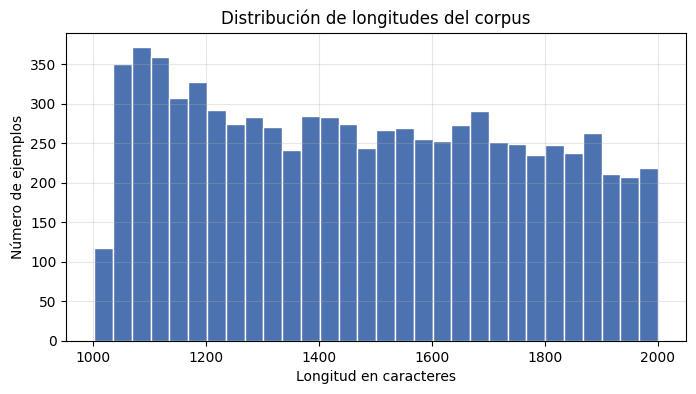

In [5]:
plt.figure(figsize=(8, 4))
plt.hist(lengths, bins=30, color="#4C72B0", edgecolor="white")
plt.title("Distribución de longitudes del corpus")
plt.xlabel("Longitud en caracteres")
plt.ylabel("Número de ejemplos")
plt.grid(alpha=0.3)
plt.show()


# Preprocesamiento

## Tokenización común

Se utiliza el tokenizador de SmolLM2-135M para las cinco configuraciones, incluido el GPT desde cero. Mantener la misma representación por subpalabras y el mismo vocabulario permite comparar la pérdida y la perplejidad sobre objetivos equivalentes. Se conserva la indentación y los saltos de línea del código.

In [6]:
TOKENIZER_NAME = "HuggingFaceTB/SmolLM2-135M"
CONTEXT_LENGTH = 256
VOCAB_SIZE = 49152

tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)

print("Tokenizador:", TOKENIZER_NAME)
print("Tamaño del vocabulario:", tokenizer.vocab_size)
print("¿Token EOS disponible?:", tokenizer.eos_token is not None)
print("Token EOS:", tokenizer.eos_token)


config.json:   0%|          | 0.00/704 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.66k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

Tokenizador: HuggingFaceTB/SmolLM2-135M
Tamaño del vocabulario: 49152
¿Token EOS disponible?: True
Token EOS: <|endoftext|>


## Construcción de secuencias

La función siguiente concatena los tokens de los archivos y añade EOS entre ellos. Después crea bloques completos de 256 tokens, sin padding, y descarta el sobrante final de cada partición, inferior a 256 tokens.

Aquí solo se define la transformación. Su aplicación se realiza después de separar los archivos en entrenamiento, validación y prueba: así, un archivo no se fragmenta entre particiones. Los bloques pueden cruzar límites entre archivos de una misma partición, marcados por EOS.

In [7]:
def tokenize_and_chunk(code_list, tokenizer, context_length=256, desc="Tokenizando"):
    if tokenizer.eos_token_id is None:
        raise ValueError("El tokenizador debe tener un token EOS.")

    all_input_ids = []

    for code in tqdm(code_list, desc=desc):
        token_ids = tokenizer(
            code,
            add_special_tokens=False,
            truncation=False,
            return_attention_mask=False
        )["input_ids"]

        all_input_ids.extend(token_ids)

        all_input_ids.append(tokenizer.eos_token_id)

    n_blocks = len(all_input_ids) // context_length
    used_tokens = n_blocks * context_length

    blocks = [
        all_input_ids[start:start + context_length]
        for start in range(0, used_tokens, context_length)
    ]

    discarded_tokens = len(all_input_ids) - used_tokens

    print(
        f"{desc}: {len(code_list)} archivos → "
        f"{len(blocks)} bloques de {context_length} tokens."
    )
    print(f"Tokens sobrantes descartados: {discarded_tokens}")

    return blocks


# Split train / validación / prueba

## Separación por archivo

Se mezclan los índices con un generador local y semilla 42. Se reservan 6.400 archivos para entrenamiento, 800 para validación y 800 para prueba. Las aserciones verifican que los índices son disjuntos.

Esta comprobación evita compartir el mismo registro entre particiones, pero no demuestra ausencia de archivos duplicados o muy similares, ni ausencia de esos archivos en el preentrenamiento de SmolLM2. No se realizó una auditoría adicional de similitud.

In [8]:
assert len(corpus) == 8000, (
    f"Se esperaban 8000 archivos y se encontraron {len(corpus)}."
)

assert all(1000 <= len(code) <= 2000 for code in corpus), (
    "Hay archivos fuera del rango obligatorio de caracteres."
)

split_rng = random.Random(SEED)

file_indices = list(range(len(corpus)))
split_rng.shuffle(file_indices)

train_indices = file_indices[:6400]
val_indices = file_indices[6400:7200]
test_indices = file_indices[7200:8000]

train_codes = [corpus[i] for i in train_indices]
val_codes = [corpus[i] for i in val_indices]
test_codes = [corpus[i] for i in test_indices]

assert set(train_indices).isdisjoint(val_indices)
assert set(train_indices).isdisjoint(test_indices)
assert set(val_indices).isdisjoint(test_indices)

assert len(train_codes) == 6400
assert len(val_codes) == 800
assert len(test_codes) == 800

print("Archivos de entrenamiento:", len(train_codes))
print("Archivos de validación:", len(val_codes))
print("Archivos de prueba:", len(test_codes))
print("Verificación: no hay índices compartidos entre particiones.")


Archivos de entrenamiento: 6400
Archivos de validación: 800
Archivos de prueba: 800
Verificación: no hay índices compartidos entre particiones.


## Segmentación independiente de las particiones

Cada grupo se tokeniza y segmenta por separado. En la ejecución registrada se obtuvieron 10.761 bloques de entrenamiento, 1.392 de validación y 1.365 de prueba. Estos conteos son distintos de los de archivos porque un archivo puede aportar varios bloques.

Se conserva `test_codes` para seleccionar los prompts de generación a partir de los 800 archivos originales. Los bloques de prueba se utilizan para calcular perplejidad.

In [9]:
assert CONTEXT_LENGTH == 256
assert tokenizer.vocab_size == 49152

train_blocks = tokenize_and_chunk(
    train_codes,
    tokenizer,
    context_length=CONTEXT_LENGTH,
    desc="Entrenamiento"
)

val_blocks = tokenize_and_chunk(
    val_codes,
    tokenizer,
    context_length=CONTEXT_LENGTH,
    desc="Validación"
)

test_blocks = tokenize_and_chunk(
    test_codes,
    tokenizer,
    context_length=CONTEXT_LENGTH,
    desc="Prueba"
)

for name, blocks in [
    ("Entrenamiento", train_blocks),
    ("Validación", val_blocks),
    ("Prueba", test_blocks),
]:
    assert len(blocks) > 0, f"No hay bloques en {name}."
    assert all(len(block) == 256 for block in blocks), (
        f"Hay bloques con longitud incorrecta en {name}."
    )

print("\nRESUMEN")
print("Archivos train / validación / prueba:",
      len(train_codes), len(val_codes), len(test_codes))
print("Bloques train / validación / prueba:",
      len(train_blocks), len(val_blocks), len(test_blocks))
print("Longitud de cada bloque:", CONTEXT_LENGTH)


Entrenamiento:   0%|          | 0/6400 [00:00<?, ?it/s]

Entrenamiento: 6400 archivos → 10761 bloques de 256 tokens.
Tokens sobrantes descartados: 95


Validación:   0%|          | 0/800 [00:00<?, ?it/s]

Validación: 800 archivos → 1392 bloques de 256 tokens.
Tokens sobrantes descartados: 218


Prueba:   0%|          | 0/800 [00:00<?, ?it/s]

Prueba: 800 archivos → 1365 bloques de 256 tokens.
Tokens sobrantes descartados: 110

RESUMEN
Archivos train / validación / prueba: 6400 800 800
Bloques train / validación / prueba: 10761 1392 1365
Longitud de cada bloque: 256


## Interfaz de datos para PyTorch

Cada elemento del dataset es un tensor de identificadores de 256 tokens. Los mismos bloques se reutilizan en todos los modelos; las etiquetas de predicción se desplazan dentro del GPT o internamente en la implementación de Hugging Face.

In [10]:
class CodeBlockDataset(Dataset):
    def __init__(self, blocks):
        self.blocks = blocks

    def __len__(self):
        return len(self.blocks)

    def __getitem__(self, idx):
        input_ids = torch.tensor(self.blocks[idx], dtype=torch.long)
        return input_ids


# Modelo desde cero

## Arquitectura GPT decoder-only

El modelo tiene seis bloques Transformer, dimensión interna de 384, seis cabezas de atención y dropout de 0.1. Combina embeddings de tokens y posiciones aprendidas, atención causal, conexiones residuales, normalización previa y una red feed-forward con activación GELU.

La máscara triangular impide acceder a tokens futuros. La salida tiene 49.152 logits por posición. Para el objetivo causal se compara el logit de la posición t con el token de la posición t+1: cada bloque aporta 255 objetivos. La arquitectura tiene 48.494.592 parámetros en la configuración registrada.

In [11]:
@dataclass
class GPTConfig:
    vocab_size: int = VOCAB_SIZE
    context_length: int = CONTEXT_LENGTH
    d_model: int = 384
    n_heads: int = 6
    n_layers: int = 6
    dropout: float = 0.1

class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.d_model % config.n_heads == 0

        self.d_model = config.d_model
        self.n_heads = config.n_heads
        self.head_dim = config.d_model // config.n_heads

        self.qkv_projection = nn.Linear(config.d_model, 3 * config.d_model)
        self.output_projection = nn.Linear(config.d_model, config.d_model)
        self.dropout = nn.Dropout(config.dropout)

        mask = torch.tril(
            torch.ones(config.context_length, config.context_length)
        )
        self.register_buffer("causal_mask", mask.bool())

    def forward(self, x):
        batch_size, sequence_length, d_model = x.shape

        qkv = self.qkv_projection(x)
        q, k, v = qkv.split(self.d_model, dim=2)

        q = q.view(batch_size, sequence_length, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(batch_size, sequence_length, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(batch_size, sequence_length, self.n_heads, self.head_dim).transpose(1, 2)

        attention_scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)

        causal_mask = self.causal_mask[:sequence_length, :sequence_length]
        attention_scores = attention_scores.masked_fill(~causal_mask, float("-inf"))

        attention_weights = F.softmax(attention_scores, dim=-1)
        attention_weights = self.dropout(attention_weights)

        attention_output = attention_weights @ v
        attention_output = attention_output.transpose(1, 2).contiguous()
        attention_output = attention_output.view(batch_size, sequence_length, d_model)

        return self.output_projection(attention_output)

class TransformerBlock(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.layer_norm_1 = nn.LayerNorm(config.d_model)
        self.attention = CausalSelfAttention(config)

        self.layer_norm_2 = nn.LayerNorm(config.d_model)
        self.feed_forward = nn.Sequential(
            nn.Linear(config.d_model, 4 * config.d_model),
            nn.GELU(),
            nn.Linear(4 * config.d_model, config.d_model),
            nn.Dropout(config.dropout)
        )

    def forward(self, x):
        x = x + self.attention(self.layer_norm_1(x))
        x = x + self.feed_forward(self.layer_norm_2(x))
        return x

class GPTFromScratch(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config

        self.token_embedding = nn.Embedding(
            config.vocab_size, config.d_model
        )
        self.position_embedding = nn.Embedding(
            config.context_length, config.d_model
        )
        self.embedding_dropout = nn.Dropout(config.dropout)

        self.blocks = nn.ModuleList([
            TransformerBlock(config)
            for _ in range(config.n_layers)
        ])

        self.final_layer_norm = nn.LayerNorm(config.d_model)

        self.language_modeling_head = nn.Linear(
            config.d_model,
            config.vocab_size,
            bias=False
        )

    def forward(self, input_ids, labels=None):
        batch_size, sequence_length = input_ids.shape

        if sequence_length > self.config.context_length:
            raise ValueError(
                "La secuencia supera la longitud de contexto configurada."
            )

        positions = torch.arange(
            sequence_length,
            device=input_ids.device
        )

        x = (
            self.token_embedding(input_ids)
            + self.position_embedding(positions)
        )
        x = self.embedding_dropout(x)

        for block in self.blocks:
            x = block(x)

        x = self.final_layer_norm(x)
        logits = self.language_modeling_head(x)

        loss = None

        if labels is not None:

            shift_logits = logits[:, :-1, :].contiguous()
            shift_labels = labels[:, 1:].contiguous()

            loss = F.cross_entropy(
                shift_logits.reshape(-1, self.config.vocab_size),
                shift_labels.reshape(-1),
                ignore_index=-100
            )

        return logits, loss


## Lotes y acumulación

Se procesan microbatches de ocho secuencias y se acumulan dos antes de actualizar los pesos: el batch efectivo habitual es 16. No se descarta el último lote; el entrenamiento pondera su contribución según el tamaño real del grupo de acumulación.

In [12]:
train_dataset = CodeBlockDataset(train_blocks)
val_dataset = CodeBlockDataset(val_blocks)
test_dataset = CodeBlockDataset(test_blocks)

MICRO_BATCH_SIZE = 8
GRAD_ACCUM_STEPS = 2

train_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=MICRO_BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    generator=train_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=MICRO_BATCH_SIZE,
    shuffle=False,
    drop_last=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=MICRO_BATCH_SIZE,
    shuffle=False,
    drop_last=False
)

print("Bloques de entrenamiento:", len(train_dataset))
print("Bloques de validación:", len(val_dataset))
print("Bloques de prueba:", len(test_dataset))

print("\nLotes de entrenamiento:", len(train_loader))
print("Lotes de validación:", len(val_loader))
print("Lotes de prueba:", len(test_loader))

print("\nMicrobatch:", MICRO_BATCH_SIZE)
print("Acumulación:", GRAD_ACCUM_STEPS)
print(
    "Batch efectivo habitual:",
    MICRO_BATCH_SIZE * GRAD_ACCUM_STEPS
)


Bloques de entrenamiento: 10761
Bloques de validación: 1392
Bloques de prueba: 1365

Lotes de entrenamiento: 1346
Lotes de validación: 174
Lotes de prueba: 171

Microbatch: 8
Acumulación: 2
Batch efectivo habitual: 16


## Optimización y selección del checkpoint

Se entrena durante tres épocas con AdamW, tasa de aprendizaje de 3e-4 y weight decay de 0.01. La precisión mixta float16 y GradScaler reducen el costo de cómputo conservando escalado de gradientes; el recorte a norma 1 limita actualizaciones extremas.

La pérdida de validación se calcula al final de cada época, ponderada por tokens. Se guarda el checkpoint de menor pérdida de validación y se recupera al finalizar, sin consultar el conjunto de prueba. En la ejecución registrada se seleccionó la época 3.

In [13]:
assert DEVICE.type == "cuda", "Activa la GPU antes de entrenar."

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

train_generator.manual_seed(SEED)

AMP_DTYPE = torch.float16
SCRATCH_LEARNING_RATE = 3e-4
SCRATCH_EPOCHS = 3

os.makedirs("checkpoints", exist_ok=True)

SCRATCH_CHECKPOINT_PATH = (
    "checkpoints/gpt_desde_cero_corregido.pt"
)

gpt_config = GPTConfig()
scratch_model = GPTFromScratch(gpt_config).to(DEVICE)

scratch_optimizer = torch.optim.AdamW(
    scratch_model.parameters(),
    lr=SCRATCH_LEARNING_RATE,
    weight_decay=0.01
)

scratch_scaler = torch.amp.GradScaler("cuda")

print(
    "Parámetros:",
    f"{sum(p.numel() for p in scratch_model.parameters()):,}"
)
print("Precisión de cálculo:", AMP_DTYPE)
print("Épocas:", SCRATCH_EPOCHS)

@torch.no_grad()
def evaluate_scratch_loss(model, loader, device):
    was_training = model.training
    model.eval()

    total_nll = 0.0
    total_tokens = 0

    try:
        for batch in loader:
            input_ids = batch.to(device)

            with torch.autocast(
                device_type="cuda",
                dtype=AMP_DTYPE
            ):
                logits, loss = model(
                    input_ids,
                    labels=input_ids
                )

            if not torch.isfinite(loss).item():
                raise RuntimeError(
                    "Pérdida no finita durante validación."
                )

            n_tokens = (
                input_ids.shape[0]
                * (input_ids.shape[1] - 1)
            )

            total_nll += loss.item() * n_tokens
            total_tokens += n_tokens

            del logits, loss, input_ids

        return total_nll / total_tokens

    finally:
        model.train(was_training)

scratch_train_losses = []
scratch_val_losses = []
scratch_step_history = []

best_val_loss = float("inf")
best_scratch_epoch = None
global_micro_step = 0

torch.cuda.synchronize()
start_time = time.time()

for epoch in range(SCRATCH_EPOCHS):
    scratch_model.train()
    scratch_optimizer.zero_grad(set_to_none=True)

    epoch_nll = 0.0
    epoch_tokens = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"GPT | Época {epoch + 1}/{SCRATCH_EPOCHS}"
    )

    for step, batch in enumerate(progress_bar):
        input_ids = batch.to(DEVICE)

        group_start_step = (
            step // GRAD_ACCUM_STEPS
        ) * GRAD_ACCUM_STEPS

        remaining_examples = (
            len(train_dataset)
            - group_start_step * MICRO_BATCH_SIZE
        )

        group_examples = min(
            MICRO_BATCH_SIZE * GRAD_ACCUM_STEPS,
            remaining_examples
        )

        with torch.autocast(
            device_type="cuda",
            dtype=AMP_DTYPE
        ):
            logits, raw_loss = scratch_model(
                input_ids,
                labels=input_ids
            )

            backward_loss = raw_loss * (
                input_ids.shape[0] / group_examples
            )

        if not torch.isfinite(raw_loss).item():
            raise RuntimeError(
                "La pérdida es NaN o infinita. Se requiere revisar la estabilidad numérica."
            )

        scratch_scaler.scale(backward_loss).backward()

        n_tokens = (
            input_ids.shape[0]
            * (input_ids.shape[1] - 1)
        )
        loss_value = raw_loss.item()

        epoch_nll += loss_value * n_tokens
        epoch_tokens += n_tokens
        global_micro_step += 1

        if global_micro_step % 50 == 0:
            scratch_step_history.append({
                "micro_step": global_micro_step,
                "epoch": epoch + 1,
                "train_batch_loss": loss_value
            })

        end_of_group = (
            (step + 1) % GRAD_ACCUM_STEPS == 0
            or (step + 1) == len(train_loader)
        )

        if end_of_group:
            scratch_scaler.unscale_(scratch_optimizer)

            torch.nn.utils.clip_grad_norm_(
                scratch_model.parameters(),
                max_norm=1.0
            )

            scratch_scaler.step(scratch_optimizer)
            scratch_scaler.update()
            scratch_optimizer.zero_grad(set_to_none=True)

        progress_bar.set_postfix(
            loss=f"{loss_value:.4f}",
            mean_loss=f"{epoch_nll / epoch_tokens:.4f}"
        )

        del logits, raw_loss, backward_loss, input_ids

    train_loss = epoch_nll / epoch_tokens

    val_loss = evaluate_scratch_loss(
        scratch_model,
        val_loader,
        DEVICE
    )

    scratch_train_losses.append(train_loss)
    scratch_val_losses.append(val_loss)

    print(
        f"Época {epoch + 1}: "
        f"train = {train_loss:.4f} | "
        f"validación = {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_scratch_epoch = epoch + 1

        torch.save(
            {
                "model_state_dict": scratch_model.state_dict(),
                "config": dict(gpt_config.__dict__),
                "epoch": best_scratch_epoch,
                "best_val_loss": best_val_loss,
                "tokenizer_name": TOKENIZER_NAME,
                "seed": SEED,
                "objective": "next_token_prediction"
            },
            SCRATCH_CHECKPOINT_PATH
        )

        print("Mejor checkpoint actualizado.")

torch.cuda.synchronize()
scratch_training_minutes = (
    time.time() - start_time
) / 60

checkpoint = torch.load(
    SCRATCH_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

scratch_model.load_state_dict(
    checkpoint["model_state_dict"]
)
scratch_model.eval()

del checkpoint
gc.collect()

print("\nENTRENAMIENTO TERMINADO")
print("Mejor época:", best_scratch_epoch)
print("Mejor pérdida de validación:", round(best_val_loss, 4))
print("Tiempo total:", round(scratch_training_minutes, 2), "minutos")
print("Checkpoint:", SCRATCH_CHECKPOINT_PATH)


Parámetros: 48,494,592
Precisión de cálculo: torch.float16
Épocas: 3


GPT | Época 1/3:   0%|          | 0/1346 [00:00<?, ?it/s]

Época 1: train = 5.2384 | validación = 4.2844
Mejor checkpoint actualizado.


GPT | Época 2/3:   0%|          | 0/1346 [00:00<?, ?it/s]

Época 2: train = 3.9537 | validación = 3.7836
Mejor checkpoint actualizado.


GPT | Época 3/3:   0%|          | 0/1346 [00:00<?, ?it/s]

Época 3: train = 3.4762 | validación = 3.5346
Mejor checkpoint actualizado.

ENTRENAMIENTO TERMINADO
Mejor época: 3
Mejor pérdida de validación: 3.5346
Tiempo total: 4.66 minutos
Checkpoint: checkpoints/gpt_desde_cero_corregido.pt


## Evolución de la pérdida

Se comparan promedios por época de entrenamiento y validación y se conservan los historiales en CSV. El descenso de validación en las tres épocas no muestra deterioro en las mediciones disponibles. No constituye una garantía de ausencia de sobreajuste.

| Época | Entrenamiento | Validación |
|---|---:|---:|
| 1 | 5.2384 | 4.2844 |
| 2 | 3.9537 | 3.7836 |
| 3 | 3.4762 | 3.5346 |

La figura conservada se reconstruyó a partir de los promedios registrados, redondeados a cuatro decimales; al ejecutar la celda se grafica el historial calculado en esa ejecución.

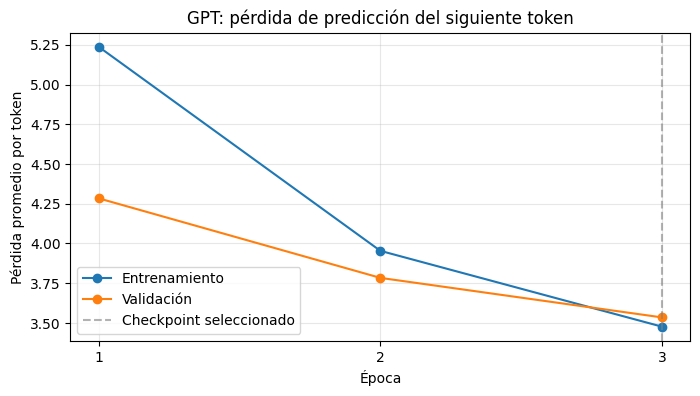

Historiales guardados.


In [14]:
epochs = range(1, len(scratch_train_losses) + 1)

plt.figure(figsize=(8, 4))

plt.plot(
    epochs,
    scratch_train_losses,
    marker="o",
    label="Entrenamiento"
)

plt.plot(
    epochs,
    scratch_val_losses,
    marker="o",
    label="Validación"
)

plt.axvline(
    best_scratch_epoch,
    color="gray",
    linestyle="--",
    alpha=0.6,
    label="Checkpoint seleccionado"
)

plt.xticks(list(epochs))
plt.title("GPT: pérdida de predicción del siguiente token")
plt.xlabel("Época")
plt.ylabel("Pérdida promedio por token")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

pd.DataFrame({
    "epoch": list(epochs),
    "train_loss": scratch_train_losses,
    "val_loss": scratch_val_losses
}).to_csv(
    "checkpoints/gpt_corregido_historial.csv",
    index=False
)

pd.DataFrame(scratch_step_history).to_csv(
    "checkpoints/gpt_corregido_pasos.csv",
    index=False
)

print("Historiales guardados.")


## Gestión de memoria

Después de guardar el checkpoint se liberan el modelo, el optimizador y el escalador antes de cargar SmolLM2. Esta operación permite ejecutar los entrenamientos de forma secuencial en una única GPU.

In [15]:
assert os.path.isfile(SCRATCH_CHECKPOINT_PATH), (
    "No se encontró el checkpoint del GPT."
)

for variable_name in [
    "scratch_model",
    "scratch_optimizer",
    "scratch_scaler",
    "model_135m"
]:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()
torch.cuda.empty_cache()

print("Checkpoint GPT encontrado:", SCRATCH_CHECKPOINT_PATH)
print(
    "Memoria GPU reservada:",
    round(torch.cuda.memory_reserved() / 1024**3, 2),
    "GB"
)


Checkpoint GPT encontrado: checkpoints/gpt_desde_cero_corregido.pt
Memoria GPU reservada: 0.04 GB


# Finetuning de los modelos pre-entrenados

## Procedimiento de adaptación completa

Los modelos se inicializan con sus pesos preentrenados y se verifica que todos sus parámetros sean entrenables. No se usan LoRA, QLoRA ni capas congeladas. Cada tamaño se entrena una época con AdamW, weight decay de 0.01 y recorte de gradientes a norma 1.

Se combinan precisión mixta float16 con GradScaler, acumulación de gradientes y gradient checkpointing. Esta última técnica reduce activaciones almacenadas a cambio de recalcularlas durante el backward. La caché de atención se desactiva durante el entrenamiento.

La validación se mide antes y después de la época; el historial de entrenamiento registra pérdidas medias por intervalos de 100 microbatches. No se registraron validaciones intermedias durante esa época: las figuras no deben interpretarse como curvas continuas de validación.

In [16]:
FINETUNE_MICRO_BATCH_SIZE = 4
FINETUNE_GRAD_ACCUM = 4

finetune_train_loader = DataLoader(
    train_dataset,
    batch_size=FINETUNE_MICRO_BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    generator=torch.Generator().manual_seed(SEED)
)

finetune_val_loader = DataLoader(
    val_dataset,
    batch_size=FINETUNE_MICRO_BATCH_SIZE,
    shuffle=False,
    drop_last=False
)

@torch.no_grad()
def evaluate_hf_loss(model, loader):
    was_training = model.training
    model.eval()

    total_nll = 0.0
    total_tokens = 0

    try:
        for batch in loader:
            input_ids = batch.to(DEVICE)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                outputs = model(
                    input_ids=input_ids,
                    labels=input_ids,
                    use_cache=False
                )
                loss = outputs.loss

            if not torch.isfinite(loss).item():
                raise RuntimeError(
                    "Pérdida no finita durante validación."
                )

            n_tokens = (
                input_ids.shape[0]
                * (input_ids.shape[1] - 1)
            )

            total_nll += loss.item() * n_tokens
            total_tokens += n_tokens

            del outputs, loss, input_ids

        return total_nll / total_tokens

    finally:
        model.train(was_training)

def finetune_hf(model_name, learning_rate):
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    finetune_train_loader.generator.manual_seed(SEED)

    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        dtype=torch.float32
    ).to(DEVICE)

    for parameter in model.parameters():
        parameter.requires_grad_(True)

    model.config.use_cache = False

    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    assert total_params == trainable_params

    print("Modelo:", model_name)
    print("Parámetros totales:", f"{total_params:,}")
    print("Parámetros entrenables:", f"{trainable_params:,}")

    print("\nEvaluando validación ANTES del finetuning...")
    baseline_val_loss = evaluate_hf_loss(
        model,
        finetune_val_loader
    )
    print("Pérdida inicial de validación:", baseline_val_loss)

    model.gradient_checkpointing_enable(
        gradient_checkpointing_kwargs={
            "use_reentrant": False
        }
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=0.01
    )

    scaler = torch.amp.GradScaler("cuda")

    model.train()
    optimizer.zero_grad(set_to_none=True)

    total_nll = 0.0
    total_tokens = 0
    window_nll = 0.0
    window_tokens = 0
    step_history = []

    torch.cuda.synchronize()
    start_time = time.time()

    progress = tqdm(
        finetune_train_loader,
        desc=f"{model_name} | 1 época"
    )

    for step, batch in enumerate(progress):
        input_ids = batch.to(DEVICE)

        group_start_step = (
            step // FINETUNE_GRAD_ACCUM
        ) * FINETUNE_GRAD_ACCUM

        remaining_examples = (
            len(train_dataset)
            - group_start_step * FINETUNE_MICRO_BATCH_SIZE
        )

        group_examples = min(
            FINETUNE_MICRO_BATCH_SIZE * FINETUNE_GRAD_ACCUM,
            remaining_examples
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(
                input_ids=input_ids,
                labels=input_ids,
                use_cache=False
            )
            raw_loss = outputs.loss

            backward_loss = raw_loss * (
                input_ids.shape[0] / group_examples
            )

        if not torch.isfinite(raw_loss).item():
            raise RuntimeError(
                "Pérdida NaN o infinita. Se requiere revisar la estabilidad numérica."
            )

        scaler.scale(backward_loss).backward()

        n_tokens = (
            input_ids.shape[0]
            * (input_ids.shape[1] - 1)
        )
        loss_value = raw_loss.item()

        total_nll += loss_value * n_tokens
        total_tokens += n_tokens

        window_nll += loss_value * n_tokens
        window_tokens += n_tokens

        end_of_group = (
            (step + 1) % FINETUNE_GRAD_ACCUM == 0
            or (step + 1) == len(finetune_train_loader)
        )

        if end_of_group:
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                1.0
            )

            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        if (
            (step + 1) % 100 == 0
            or (step + 1) == len(finetune_train_loader)
        ):
            step_history.append({
                "micro_step": step + 1,
                "train_loss": window_nll / window_tokens
            })
            window_nll = 0.0
            window_tokens = 0

        progress.set_postfix(
            loss=f"{loss_value:.4f}",
            mean_loss=f"{total_nll / total_tokens:.4f}"
        )

        del outputs, raw_loss, backward_loss, input_ids

    train_loss = total_nll / total_tokens

    del optimizer, scaler
    gc.collect()
    torch.cuda.empty_cache()

    final_val_loss = evaluate_hf_loss(
        model,
        finetune_val_loader
    )

    torch.cuda.synchronize()
    elapsed_minutes = (time.time() - start_time) / 60

    model.gradient_checkpointing_disable()
    model.eval()

    print("\nFINETUNING TERMINADO")
    print("Pérdida inicial validación:", round(baseline_val_loss, 4))
    print("Pérdida entrenamiento:", round(train_loss, 4))
    print("Pérdida final validación:", round(final_val_loss, 4))
    print("Tiempo entrenamiento + validación final:",
          round(elapsed_minutes, 2), "minutos")

    return (
        model,
        baseline_val_loss,
        train_loss,
        final_val_loss,
        step_history,
        elapsed_minutes
    )


## SmolLM2-135M: entrenamiento

Se usa una tasa de 5e-5, microbatch de cuatro y acumulación de cuatro. El batch efectivo habitual es 16. La ejecución registrada actualizó los 134.515.008 parámetros del modelo.

In [17]:
SMOL_135M_NAME = "HuggingFaceTB/SmolLM2-135M"

(
    model_135m,
    baseline_val_135m,
    train_loss_135m,
    val_loss_135m,
    history_135m,
    time_135m
) = finetune_hf(
    model_name=SMOL_135M_NAME,
    learning_rate=5e-5
)


model.safetensors: reconstructing file:   0%|          |  0.00B /  269MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

Modelo: HuggingFaceTB/SmolLM2-135M
Parámetros totales: 134,515,008
Parámetros entrenables: 134,515,008

Evaluando validación ANTES del finetuning...
Pérdida inicial de validación: 1.7627746567301366


HuggingFaceTB/SmolLM2-135M | 1 época:   0%|          | 0/2691 [00:00<?, ?it/s]


FINETUNING TERMINADO
Pérdida inicial validación: 1.7628
Pérdida entrenamiento: 1.629
Pérdida final validación: 1.5848
Tiempo entrenamiento + validación final: 12.82 minutos


## SmolLM2-135M: historial y validación

La curva muestra la pérdida media de cada intervalo de entrenamiento, mientras que las barras comparan validación antes y después. En la ejecución registrada la validación pasó de 1.7628 a 1.5848; el promedio de entrenamiento fue 1.6290.

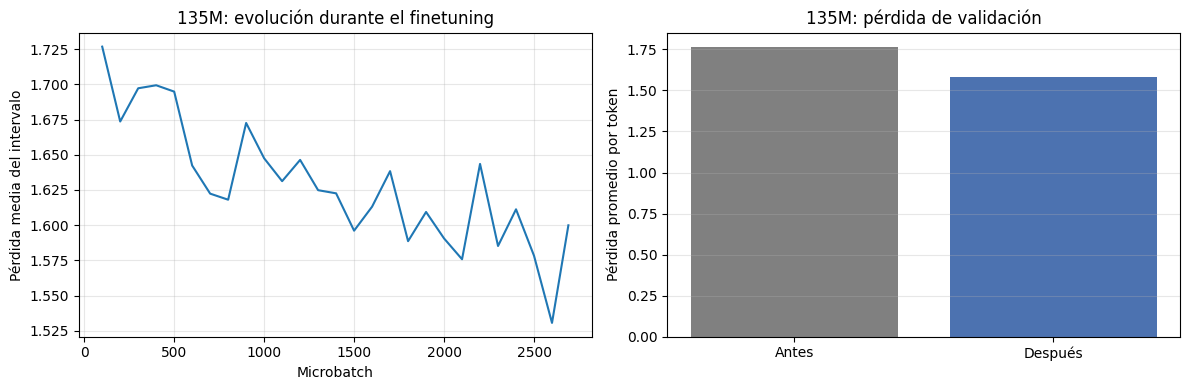

In [18]:
history_df_135m = pd.DataFrame(history_135m)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_df_135m["micro_step"],
    history_df_135m["train_loss"]
)
axes[0].set_title("135M: evolución durante el finetuning")
axes[0].set_xlabel("Microbatch")
axes[0].set_ylabel("Pérdida media del intervalo")
axes[0].grid(alpha=0.3)

axes[1].bar(
    ["Antes", "Después"],
    [baseline_val_135m, val_loss_135m],
    color=["gray", "#4C72B0"]
)
axes[1].set_title("135M: pérdida de validación")
axes[1].set_ylabel("Pérdida promedio por token")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## Persistencia del modelo de 135M

Se guarda un único checkpoint mediante torch.save con pesos, configuración, identificador del modelo base y métricas de validación. Los historiales se conservan por separado. No se guardan estados del optimizador: el archivo permite evaluar el modelo, pero no retomar exactamente el estado de optimización.

In [19]:
CHECKPOINT_135M_PATH = (
    "checkpoints/smollm2_135m_finetuned_corregido.pt"
)

torch.save(
    {
        "model_state_dict": model_135m.state_dict(),
        "model_name": SMOL_135M_NAME,
        "config": model_135m.config.to_dict(),
        "tokenizer_name": TOKENIZER_NAME,
        "context_length": CONTEXT_LENGTH,
        "seed": SEED,
        "epochs": 1,
        "baseline_val_loss": baseline_val_135m,
        "train_loss": train_loss_135m,
        "final_val_loss": val_loss_135m
    },
    CHECKPOINT_135M_PATH
)

pd.DataFrame(history_135m).to_csv(
    "checkpoints/smollm2_135m_corregido_historial.csv",
    index=False
)

assert os.path.getsize(CHECKPOINT_135M_PATH) > 0

print("Checkpoint guardado:", CHECKPOINT_135M_PATH)
print(
    "Tamaño:",
    round(os.path.getsize(CHECKPOINT_135M_PATH) / 1024**2, 1),
    "MB"
)


Checkpoint guardado: checkpoints/smollm2_135m_finetuned_corregido.pt
Tamaño: 513.2 MB


## Liberación de memoria

Una vez guardados los pesos, se elimina el modelo de 135M de la GPU. El siguiente modelo se carga de forma independiente para evitar mantener ambos en memoria.

In [20]:
if "model_135m" in globals():
    del model_135m

gc.collect()
torch.cuda.empty_cache()

print(
    "Memoria GPU reservada:",
    round(torch.cuda.memory_reserved() / 1024**3, 2),
    "GB"
)


Memoria GPU reservada: 0.04 GB


## SmolLM2-360M: configuración de memoria

Se reduce el microbatch a dos y se acumulan ocho microbatches, manteniendo un batch efectivo habitual de 16. La menor cantidad de secuencias simultáneas limita las activaciones en memoria; las técnicas de precisión mixta y checkpointing son las mismas del modelo anterior.

In [21]:
FINETUNE_MICRO_BATCH_SIZE = 2
FINETUNE_GRAD_ACCUM = 8

finetune_train_loader = DataLoader(
    train_dataset,
    batch_size=FINETUNE_MICRO_BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    generator=torch.Generator().manual_seed(SEED)
)

finetune_val_loader = DataLoader(
    val_dataset,
    batch_size=FINETUNE_MICRO_BATCH_SIZE,
    shuffle=False,
    drop_last=False
)

assert len(train_dataset) == 10761
assert len(val_dataset) == 1392

print("Microbatch:", FINETUNE_MICRO_BATCH_SIZE)
print("Acumulación:", FINETUNE_GRAD_ACCUM)
print(
    "Batch efectivo habitual:",
    FINETUNE_MICRO_BATCH_SIZE * FINETUNE_GRAD_ACCUM
)
print("Lotes de entrenamiento:", len(finetune_train_loader))
print("Lotes de validación:", len(finetune_val_loader))


Microbatch: 2
Acumulación: 8
Batch efectivo habitual: 16
Lotes de entrenamiento: 5381
Lotes de validación: 696


## SmolLM2-360M: entrenamiento

Se utiliza una tasa de aprendizaje de 3e-5 durante una época. La ejecución registrada actualizó los 361.821.120 parámetros del modelo. Los datos de entrenamiento y validación son los mismos que para 135M.

In [22]:
SMOL_360M_NAME = "HuggingFaceTB/SmolLM2-360M"

(
    model_360m,
    baseline_val_360m,
    train_loss_360m,
    val_loss_360m,
    history_360m,
    time_360m
) = finetune_hf(
    model_name=SMOL_360M_NAME,
    learning_rate=3e-5
)


config.json:   0%|          | 0.00/689 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  724MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

Modelo: HuggingFaceTB/SmolLM2-360M
Parámetros totales: 361,821,120
Parámetros entrenables: 361,821,120

Evaluando validación ANTES del finetuning...
Pérdida inicial de validación: 1.5070723319404769


HuggingFaceTB/SmolLM2-360M | 1 época:   0%|          | 0/5381 [00:00<?, ?it/s]


FINETUNING TERMINADO
Pérdida inicial validación: 1.5071
Pérdida entrenamiento: 1.401
Pérdida final validación: 1.3768
Tiempo entrenamiento + validación final: 28.07 minutos


## Persistencia y respaldo de los modelos

Se guarda el checkpoint de 360M y se copian los tres checkpoints y sus historiales a la ubicación de respaldo configurada. La comprobación de tamaño confirma que se produjo la copia; no reemplaza una prueba de carga o una verificación criptográfica.

In [23]:
CHECKPOINT_360M_PATH = (
    "checkpoints/smollm2_360m_finetuned_corregido.pt"
)

torch.save(
    {
        "model_state_dict": model_360m.state_dict(),
        "model_name": SMOL_360M_NAME,
        "config": model_360m.config.to_dict(),
        "tokenizer_name": TOKENIZER_NAME,
        "context_length": CONTEXT_LENGTH,
        "seed": SEED,
        "epochs": 1,
        "baseline_val_loss": baseline_val_360m,
        "train_loss": train_loss_360m,
        "final_val_loss": val_loss_360m
    },
    CHECKPOINT_360M_PATH
)

pd.DataFrame(history_360m).to_csv(
    "checkpoints/smollm2_360m_corregido_historial.csv",
    index=False
)

assert os.path.getsize(CHECKPOINT_360M_PATH) > 0

backup_names = [
    "gpt_desde_cero_corregido.pt",
    "smollm2_135m_finetuned_corregido.pt",
    "smollm2_360m_finetuned_corregido.pt",
    "gpt_corregido_historial.csv",
    "gpt_corregido_pasos.csv",
    "smollm2_135m_corregido_historial.csv",
    "smollm2_360m_corregido_historial.csv"
]

for filename in backup_names:
    source_path = os.path.join("checkpoints", filename)
    destination_path = os.path.join(BACKUP_DIR, filename)

    assert os.path.isfile(source_path), (
        f"Falta el archivo: {source_path}"
    )

    shutil.copy2(source_path, destination_path)

    assert (
        os.path.getsize(source_path)
        == os.path.getsize(destination_path)
    )

    print("Respaldo verificado:", filename)

print("\nLos tres checkpoints están respaldados.")


Respaldo verificado: gpt_desde_cero_corregido.pt
Respaldo verificado: smollm2_135m_finetuned_corregido.pt
Respaldo verificado: smollm2_360m_finetuned_corregido.pt
Respaldo verificado: gpt_corregido_historial.csv
Respaldo verificado: gpt_corregido_pasos.csv
Respaldo verificado: smollm2_135m_corregido_historial.csv
Respaldo verificado: smollm2_360m_corregido_historial.csv

Los tres checkpoints están respaldados.


## SmolLM2-360M: historial y validación

La validación registrada disminuyó de 1.5071 a 1.3768. El promedio de entrenamiento fue 1.4010. El tiempo medido de entrenamiento y validación final fue de 28.67 minutos, frente a 13.4 minutos para 135M; estos tiempos dependen del hardware y no incluyen todas las etapas del proyecto.

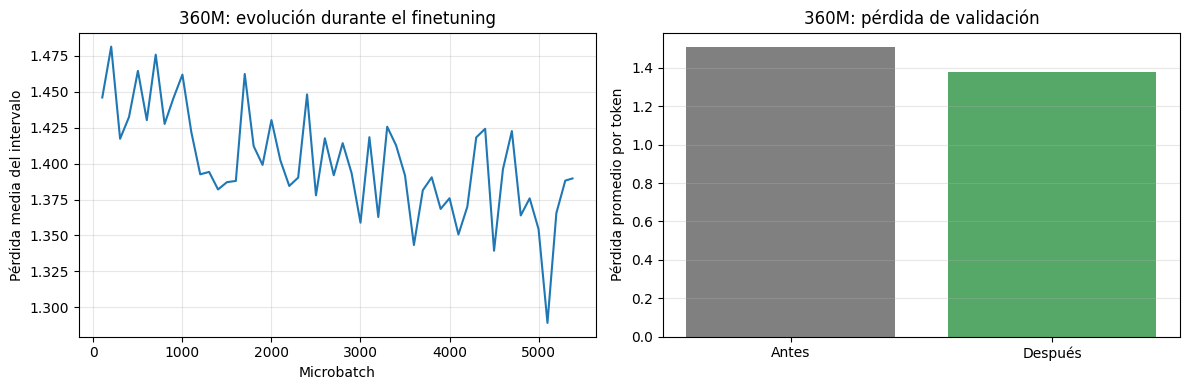

In [24]:
history_df_360m = pd.DataFrame(history_360m)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_df_360m["micro_step"],
    history_df_360m["train_loss"]
)
axes[0].set_title("360M: evolución durante el finetuning")
axes[0].set_xlabel("Microbatch")
axes[0].set_ylabel("Pérdida media del intervalo")
axes[0].grid(alpha=0.3)

axes[1].bar(
    ["Antes", "Después"],
    [baseline_val_360m, val_loss_360m],
    color=["gray", "#55A868"]
)
axes[1].set_title("360M: pérdida de validación")
axes[1].set_ylabel("Pérdida promedio por token")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# Evaluación y comparación

## Protocolo de evaluación de perplejidad

Se evalúan las cinco configuraciones sobre los mismos bloques del conjunto
de prueba, obtenidos exclusivamente de los 800 archivos reservados para prueba.

Cada bloque contiene 256 tokens. La predicción del siguiente token permite
evaluar 255 objetivos por bloque, sin padding.

Para todas las configuraciones se extraen los logits y se aplica el mismo
desplazamiento: la posición t predice el token de la posición t+1.

La perplejidad se calcula como la exponencial de la pérdida total dividida
entre el número total de tokens objetivo. No se promedian las perplejidades
de los lotes.

Estos resultados se utilizan únicamente para el reporte final, no para
seleccionar hiperparámetros ni checkpoints.

In [25]:
evaluation_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False,
    drop_last=False
)

EXPECTED_TEST_TOKENS = len(test_dataset) * (CONTEXT_LENGTH - 1)

assert len(test_codes) == 800
assert len(test_dataset) == 1365

print("Archivos de prueba:", len(test_codes))
print("Bloques de prueba:", len(test_dataset))
print("Tokens objetivo esperados:", EXPECTED_TEST_TOKENS)

@torch.inference_mode()
def evaluate_test_perplexity(model, model_label, is_scratch=False):
    model.eval()

    total_nll = 0.0
    total_tokens = 0

    for batch in tqdm(
        evaluation_loader,
        desc=f"Prueba: {model_label}"
    ):
        input_ids = batch.to(DEVICE)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            if is_scratch:
                logits, _ = model(input_ids)
            else:
                outputs = model(
                    input_ids=input_ids,
                    use_cache=False
                )
                logits = outputs.logits
                del outputs

        shift_logits = logits[:, :-1, :].contiguous()
        shift_labels = input_ids[:, 1:].contiguous()

        batch_nll = F.cross_entropy(
            shift_logits.float().reshape(-1, VOCAB_SIZE),
            shift_labels.reshape(-1),
            reduction="sum"
        )

        if not torch.isfinite(batch_nll).item():
            raise RuntimeError(
                f"Pérdida no finita en {model_label}."
            )

        total_nll += batch_nll.item()
        total_tokens += shift_labels.numel()

        del input_ids, logits
        del shift_logits, shift_labels, batch_nll

    assert total_tokens == EXPECTED_TEST_TOKENS

    mean_nll = total_nll / total_tokens

    return {
        "Modelo": model_label,
        "Perdida_prueba": mean_nll,
        "Perplejidad": math.exp(mean_nll),
        "Tokens_evaluados": total_tokens
    }


Archivos de prueba: 800
Bloques de prueba: 1365
Tokens objetivo esperados: 348075


## Evaluación del modelo de 360M finetuned

Se aprovecha que este modelo sigue cargado al terminar el entrenamiento. Se inicializa una tabla nueva para los resultados de prueba. No se modifican hiperparámetros ni checkpoints según estas mediciones.

In [26]:
assert "model_360m" in globals(), (
    "Ejecute previamente el entrenamiento del modelo de 360M."
)

test_results = []

result_360m_ft = evaluate_test_perplexity(
    model_360m,
    model_label="SmolLM2-360M finetuned"
)

test_results.append(result_360m_ft)

print(pd.DataFrame(test_results).to_string(index=False))


Prueba: SmolLM2-360M finetuned:   0%|          | 0/683 [00:00<?, ?it/s]

                Modelo  Perdida_prueba  Perplejidad  Tokens_evaluados
SmolLM2-360M finetuned        1.344411     3.835926            348075


## Carga secuencial de las demás configuraciones

Se libera el modelo de 360M. Las funciones siguientes reconstruyen el GPT desde su configuración o cargan SmolLM2 y, cuando corresponde, sustituyen sus pesos por los del checkpoint finetuned. Cada modelo se libera después de evaluarlo.

In [27]:
del model_360m
gc.collect()
torch.cuda.empty_cache()

def load_model_for_evaluation(model_name=None, checkpoint_path=None):
    if model_name is None:

        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        config = GPTConfig(**checkpoint["config"])
        model = GPTFromScratch(config)

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

        del checkpoint

    else:

        model = AutoModelForCausalLM.from_pretrained(
            model_name,
            dtype=torch.float32
        )

        if checkpoint_path is not None:
            checkpoint = torch.load(
                checkpoint_path,
                map_location="cpu",
                weights_only=True
            )

            model.load_state_dict(
                checkpoint["model_state_dict"]
            )

            del checkpoint

        model.config.use_cache = False

    return model.to(DEVICE).eval()

def evaluate_saved_configuration(
    label,
    model_name=None,
    checkpoint_path=None
):
    model = load_model_for_evaluation(
        model_name=model_name,
        checkpoint_path=checkpoint_path
    )

    try:
        result = evaluate_test_perplexity(
            model,
            model_label=label,
            is_scratch=(model_name is None)
        )
    finally:
        del model
        gc.collect()
        torch.cuda.empty_cache()

    return result


## Comparación de perplejidad

Se evalúan las cuatro configuraciones restantes sobre exactamente los mismos bloques y objetivos. La evaluación usa autocast float16 y calcula la entropía cruzada sobre logits convertidos a float32. Todas las configuraciones reciben el mismo tratamiento numérico.

In [28]:
remaining_configurations = [
    {
        "label": "GPT desde cero",
        "checkpoint_path": SCRATCH_CHECKPOINT_PATH
    },
    {
        "label": "SmolLM2-135M original",
        "model_name": "HuggingFaceTB/SmolLM2-135M"
    },
    {
        "label": "SmolLM2-135M finetuned",
        "model_name": "HuggingFaceTB/SmolLM2-135M",
        "checkpoint_path": CHECKPOINT_135M_PATH
    },
    {
        "label": "SmolLM2-360M original",
        "model_name": "HuggingFaceTB/SmolLM2-360M"
    }
]

for configuration in remaining_configurations:
    label = configuration["label"]

    if any(row["Modelo"] == label for row in test_results):
        print("Ya evaluado:", label)
        continue

    result = evaluate_saved_configuration(**configuration)
    test_results.append(result)

    print(
        f"\n{label}: "
        f"pérdida = {result['Perdida_prueba']:.4f} | "
        f"perplejidad = {result['Perplejidad']:.4f}\n"
    )


Prueba: GPT desde cero:   0%|          | 0/683 [00:00<?, ?it/s]


GPT desde cero: pérdida = 3.5057 | perplejidad = 33.3032



Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Prueba: SmolLM2-135M original:   0%|          | 0/683 [00:00<?, ?it/s]


SmolLM2-135M original: pérdida = 1.7414 | perplejidad = 5.7053



...

Prueba: SmolLM2-135M finetuned:   0%|          | 0/683 [00:00<?, ?it/s]


SmolLM2-135M finetuned: pérdida = 1.5565 | perplejidad = 4.7423



Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Prueba: SmolLM2-360M original:   0%|          | 0/683 [00:00<?, ?it/s]


SmolLM2-360M original: pérdida = 1.4800 | perplejidad = 4.3929



## Registro de las métricas predictivas

La tabla se ordena por familia y condición de entrenamiento. Se verifica que todas las configuraciones tengan el mismo número de objetivos evaluados y se exporta el resultado a CSV.

In [29]:
model_order = [
    "GPT desde cero",
    "SmolLM2-135M original",
    "SmolLM2-135M finetuned",
    "SmolLM2-360M original",
    "SmolLM2-360M finetuned"
]

assert len(test_results) == 5

results_df = (
    pd.DataFrame(test_results)
    .set_index("Modelo")
    .loc[model_order]
    .reset_index()
)

assert results_df["Tokens_evaluados"].nunique() == 1

os.makedirs("resultados", exist_ok=True)

results_path = "resultados/perplejidad_prueba.csv"
results_df.to_csv(results_path, index=False)

shutil.copy2(
    results_path,
    os.path.join(BACKUP_DIR, "perplejidad_prueba.csv")
)

print(results_df.round(4).to_string(index=False))
print("\nTabla guardada y respaldada en Drive.")


                Modelo  Perdida_prueba  Perplejidad  Tokens_evaluados
        GPT desde cero          3.5057      33.3032            348075
 SmolLM2-135M original          1.7414       5.7053            348075
SmolLM2-135M finetuned          1.5565       4.7423            348075
 SmolLM2-360M original          1.4800       4.3929            348075
SmolLM2-360M finetuned          1.3444       3.8359            348075

Tabla guardada y respaldada en Drive.


## Protocolo de validez sintáctica

Se seleccionan 200 archivos del conjunto de prueba con semilla fija.

De cada archivo se toman los primeros 64 tokens como prompt y se generan
hasta 128 tokens nuevos. La longitud total no supera los 256 tokens
de contexto establecidos.

Se utiliza selección greedy: en cada paso se elige el token con mayor
logit. Se mantiene el mismo protocolo para las cinco configuraciones.

Se analiza el prompt junto con su continuación mediante ast.parse,
sin ejecutar el código. Si la generación alcanza el límite de tokens
y termina en una línea incompleta, se elimina esa última línea.

La validez sintáctica no verifica corrección funcional. Además, el corte
del prefijo puede ocurrir dentro de una instrucción, por lo que esta
métrica se interpreta como apoyo a la perplejidad.

### Selección reproducible de prompts

La muestra se selecciona sin reemplazo a partir de los 800 archivos de prueba. Se guardan los índices y los identificadores de los 64 tokens de cada prompt. Al usar prompts de igual longitud, la generación por lotes no requiere padding.

In [30]:
import json

SYNTAX_SEED = 42
N_SYNTAX_EXAMPLES = 200
PROMPT_TOKENS = 64
MAX_NEW_TOKENS = 128

assert PROMPT_TOKENS + MAX_NEW_TOKENS <= CONTEXT_LENGTH
assert len(test_codes) == 800

syntax_rng = random.Random(SYNTAX_SEED)

syntax_test_indices = syntax_rng.sample(
    range(len(test_codes)),
    N_SYNTAX_EXAMPLES
)

syntax_prompts = []

for test_index in syntax_test_indices:
    token_ids = tokenizer(
        test_codes[test_index],
        add_special_tokens=False,
        return_attention_mask=False
    )["input_ids"]

    assert len(token_ids) >= PROMPT_TOKENS, (
        f"El archivo {test_index} tiene menos de 64 tokens."
    )

    prompt_ids = token_ids[:PROMPT_TOKENS]

    syntax_prompts.append({
        "test_index": test_index,
        "prompt_ids": prompt_ids,
        "prompt_text": tokenizer.decode(
            prompt_ids,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )
    })

os.makedirs("resultados", exist_ok=True)

with open(
    "resultados/prompts_validez_sintactica.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        syntax_prompts,
        file,
        ensure_ascii=False,
        indent=2
    )

print("Prompts seleccionados:", len(syntax_prompts))
print("Tokens por prompt:", PROMPT_TOKENS)
print("Máximo de tokens nuevos:", MAX_NEW_TOKENS)
print("\nPrimer prompt:\n")
print(syntax_prompts[0]["prompt_text"])


Prompts seleccionados: 200
Tokens por prompt: 64
Máximo de tokens nuevos: 128

Primer prompt:

#    Licensed under the Apache License, Version 2.0 (the "License"); you may
#    not use this file except in compliance with the License. You may obtain
#    a copy of the License at
#
#         http://www.apache.org/licenses/LICENSE-2


### Generación autorregresiva y comprobación sintáctica

El siguiente bloque define el generador compartido por la evaluación y los ejemplos cualitativos de la sección siguiente. Se ubica antes de su primera llamada para permitir la ejecución de principio a fin.

En cada paso se obtienen logits, se selecciona explícitamente su argmax y se concatena el token al contexto. Esto equivale a seleccionar el token de máxima probabilidad, sin necesidad de calcular softmax. No se utiliza una función de generación de alto nivel. En SmolLM2 se reutiliza la caché de atención; el GPT recalcula el contexto.

Se detiene cada secuencia por EOS o al completar 128 tokens nuevos. Antes de ast.parse se descarta la última línea sin salto final cuando se alcanzó el límite. Este criterio es una aproximación operativa al truncamiento y puede descartar también una línea completa sin salto final. Se aplica idénticamente a todos los modelos; los textos originales y evaluados se conservan.

In [31]:
@torch.inference_mode()
def generate_code_batch(
    model,
    prompt_ids_batch,
    is_scratch=False,
    max_new_tokens=128
):
    model.eval()

    assert len(prompt_ids_batch) > 0
    prompt_length = len(prompt_ids_batch[0])

    assert all(
        len(ids) == prompt_length
        for ids in prompt_ids_batch
    )
    assert prompt_length + max_new_tokens <= CONTEXT_LENGTH

    sequences = torch.tensor(
        prompt_ids_batch,
        dtype=torch.long,
        device=DEVICE
    )

    batch_size = sequences.shape[0]

    finished = torch.zeros(
        batch_size,
        dtype=torch.bool,
        device=DEVICE
    )

    generated_ids = [[] for _ in range(batch_size)]
    stop_reasons = ["token_limit"] * batch_size

    eos_id = tokenizer.eos_token_id
    assert eos_id is not None

    past_key_values = None

    for step in range(max_new_tokens):
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            if is_scratch:

                logits, _ = model(sequences)
                next_logits = logits[:, -1, :]

            else:

                current_input = (
                    sequences
                    if past_key_values is None
                    else sequences[:, -1:]
                )

                outputs = model(
                    input_ids=current_input,
                    past_key_values=past_key_values,
                    use_cache=True
                )

                next_logits = outputs.logits[:, -1, :]
                past_key_values = outputs.past_key_values

        next_tokens = torch.argmax(
            next_logits,
            dim=-1
        )

        next_tokens = torch.where(
            finished,
            torch.full_like(next_tokens, eos_id),
            next_tokens
        )

        token_values = next_tokens.tolist()
        previously_finished = finished.tolist()

        for row, token_id in enumerate(token_values):
            if previously_finished[row]:
                continue

            if token_id == eos_id:
                stop_reasons[row] = "eos"
            else:
                generated_ids[row].append(token_id)

        finished = finished | next_tokens.eq(eos_id)

        sequences = torch.cat(
            [sequences, next_tokens.unsqueeze(1)],
            dim=1
        )

        if is_scratch:
            del logits
        else:
            del outputs

        del next_logits

        if finished.all().item():
            break

    results = []

    for row in range(batch_size):
        full_ids = (
            list(prompt_ids_batch[row])
            + generated_ids[row]
        )

        full_text = tokenizer.decode(
            full_ids,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )

        results.append({
            "generated_ids": generated_ids[row],
            "full_text": full_text,
            "stop_reason": stop_reasons[row],
            "n_generated_tokens": len(generated_ids[row])
        })

    return results

def check_python_syntax(full_text, stop_reason):
    checked_text = full_text
    removed_last_line = False

    if (
        stop_reason == "token_limit"
        and checked_text
        and not checked_text.endswith(("\n", "\r"))
    ):
        newline_position = checked_text.rfind("\n")

        checked_text = (
            checked_text[:newline_position + 1]
            if newline_position >= 0
            else ""
        )
        removed_last_line = True

    if not checked_text.strip():
        return {
            "syntax_valid": False,
            "syntax_error": "Texto vacío después del recorte",
            "checked_text": checked_text,
            "removed_last_line": removed_last_line
        }

    try:
        ast.parse(checked_text)

        valid = True
        error = None

    except (SyntaxError, ValueError) as exception:
        valid = False
        error = str(exception)

    return {
        "syntax_valid": valid,
        "syntax_error": error,
        "checked_text": checked_text,
        "removed_last_line": removed_last_line
    }


### Evaluación de 200 generaciones por configuración

Se generan lotes de ocho prompts. Los resultados detallados se escriben tras cada lote y se respaldan al completar cada modelo. Cada ejecución completa recalcula las generaciones con los pesos cargados; no reutiliza automáticamente resultados de modelos de una ejecución anterior.

In [32]:
SYNTAX_BATCH_SIZE = 8

SYNTAX_OUTPUT_DIR = "resultados/validez_sintactica"
os.makedirs(SYNTAX_OUTPUT_DIR, exist_ok=True)

syntax_protocol = {
    "seed": SYNTAX_SEED,
    "n_examples": N_SYNTAX_EXAMPLES,
    "prompt_tokens": PROMPT_TOKENS,
    "max_new_tokens": MAX_NEW_TOKENS,
    "decoding": "greedy",
    "prompt_ids": [
        item["prompt_ids"] for item in syntax_prompts
    ],
    "test_indices": [
        item["test_index"] for item in syntax_prompts
    ]
}

def save_syntax_progress(path, label, rows):
    payload = {
        "model": label,
        "protocol": syntax_protocol,
        "rows": rows
    }

    temporary_path = path + ".tmp"

    with open(temporary_path, "w", encoding="utf-8") as file:
        json.dump(
            payload,
            file,
            ensure_ascii=False,
            indent=2
        )

    os.replace(temporary_path, path)

def evaluate_syntax_configuration(
    label,
    file_slug,
    model_name=None,
    checkpoint_path=None
):
    output_path = os.path.join(
        SYNTAX_OUTPUT_DIR,
        file_slug + ".json"
    )

    rows = []

    started_at = time.time()

    if len(rows) < len(syntax_prompts):
        model = load_model_for_evaluation(
            model_name=model_name,
            checkpoint_path=checkpoint_path
        )

        try:
            progress = tqdm(
                total=len(syntax_prompts),
                initial=len(rows),
                desc=f"Sintaxis: {label}"
            )

            try:
                while len(rows) < len(syntax_prompts):
                    start = len(rows)

                    prompt_batch = syntax_prompts[
                        start:start + SYNTAX_BATCH_SIZE
                    ]

                    generations = generate_code_batch(
                        model,
                        [
                            item["prompt_ids"]
                            for item in prompt_batch
                        ],
                        is_scratch=(model_name is None),
                        max_new_tokens=MAX_NEW_TOKENS
                    )

                    for offset, (prompt, generation) in enumerate(
                        zip(prompt_batch, generations)
                    ):
                        syntax_check = check_python_syntax(
                            generation["full_text"],
                            generation["stop_reason"]
                        )

                        continuation_text = tokenizer.decode(
                            generation["generated_ids"],
                            skip_special_tokens=True,
                            clean_up_tokenization_spaces=False
                        )

                        rows.append({
                            "sample_number": start + offset,
                            "test_index": prompt["test_index"],
                            "prompt_text": prompt["prompt_text"],
                            "continuation_text": continuation_text,
                            **generation,
                            **syntax_check
                        })

                    save_syntax_progress(
                        output_path,
                        label,
                        rows
                    )

                    progress.update(len(prompt_batch))

            finally:
                progress.close()

        finally:
            del model
            gc.collect()
            torch.cuda.empty_cache()

    assert len(rows) == N_SYNTAX_EXAMPLES

    shutil.copy2(
        output_path,
        os.path.join(
            BACKUP_DIR,
            os.path.basename(output_path)
        )
    )

    valid_count = sum(
        row["syntax_valid"] for row in rows
    )

    summary = {
        "Modelo": label,
        "Generaciones_evaluadas": len(rows),
        "Generaciones_validas": valid_count,
        "Validez_sintactica_pct": (
            100.0 * valid_count / len(rows)
        ),
        "Finalizadas_por_EOS": sum(
            row["stop_reason"] == "eos"
            for row in rows
        ),
        "Ultima_linea_recortada": sum(
            row["removed_last_line"]
            for row in rows
        )
    }

    elapsed = (time.time() - started_at) / 60

    print(
        f"\n{label}: {valid_count}/{len(rows)} válidas "
        f"({summary['Validez_sintactica_pct']:.1f}%)."
    )
    print(f"Tiempo de esta ejecución: {elapsed:.2f} minutos.")
    print("Generaciones guardadas y respaldadas.\n")

    return summary


### Ejecución de la comparación sintáctica

Las cinco configuraciones usan los mismos 200 prompts, selección greedy y límite de generación. Cada ejemplo válido aporta 0.5 puntos porcentuales al resultado. Se reportan también el motivo de parada y la cantidad de últimas líneas recortadas, para documentar el protocolo.

In [33]:
syntax_configurations = [
    {
        "label": "GPT desde cero",
        "file_slug": "sintaxis_gpt_desde_cero",
        "checkpoint_path": SCRATCH_CHECKPOINT_PATH
    },
    {
        "label": "SmolLM2-135M original",
        "file_slug": "sintaxis_135m_original",
        "model_name": "HuggingFaceTB/SmolLM2-135M"
    },
    {
        "label": "SmolLM2-135M finetuned",
        "file_slug": "sintaxis_135m_finetuned",
        "model_name": "HuggingFaceTB/SmolLM2-135M",
        "checkpoint_path": CHECKPOINT_135M_PATH
    },
    {
        "label": "SmolLM2-360M original",
        "file_slug": "sintaxis_360m_original",
        "model_name": "HuggingFaceTB/SmolLM2-360M"
    },
    {
        "label": "SmolLM2-360M finetuned",
        "file_slug": "sintaxis_360m_finetuned",
        "model_name": "HuggingFaceTB/SmolLM2-360M",
        "checkpoint_path": CHECKPOINT_360M_PATH
    }
]

syntax_results = []

for configuration in syntax_configurations:
    summary = evaluate_syntax_configuration(
        **configuration
    )
    syntax_results.append(summary)

syntax_df = pd.DataFrame(syntax_results)

print(
    syntax_df[
        [
            "Modelo",
            "Generaciones_evaluadas",
            "Generaciones_validas",
            "Validez_sintactica_pct"
        ]
    ].to_string(index=False)
)


Sintaxis: GPT desde cero:   0%|          | 0/200 [00:00<?, ?it/s]


GPT desde cero: 128/200 válidas (64.0%).
Tiempo de esta ejecución: 0.42 minutos.
Generaciones guardadas y respaldadas.



Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Sintaxis: SmolLM2-135M original:   0%|          | 0/200 [00:00<?, ?it/s]


SmolLM2-135M original: 142/200 válidas (71.0%).
Tiempo de esta ejecución: 2.26 minutos.
Generaciones guardadas y respaldadas.



...

Sintaxis: SmolLM2-360M original:   0%|          | 0/200 [00:00<?, ?it/s]


SmolLM2-360M original: 142/200 válidas (71.0%).
Tiempo de esta ejecución: 2.44 minutos.
Generaciones guardadas y respaldadas.



Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Sintaxis: SmolLM2-360M finetuned:   0%|          | 0/200 [00:00<?, ?it/s]


SmolLM2-360M finetuned: 147/200 válidas (73.5%).
Tiempo de esta ejecución: 2.53 minutos.
Generaciones guardadas y respaldadas.

                Modelo  Generaciones_evaluadas  Generaciones_validas  Validez_sintactica_pct
        GPT desde cero                     200                   128                    64.0
 SmolLM2-135M original                     200                   142                    71.0
SmolLM2-135M finetuned                     200                   146                    73.0
 SmolLM2-360M original                     200                   142                    71.0
SmolLM2-360M finetuned                     200                   147                    73.5


## Tabla integrada de resultados

Se unen las métricas por el nombre de la configuración y se comprueba la correspondencia uno a uno. El CSV final reúne pérdida, perplejidad y validez sintáctica sin promediar métricas de conjuntos diferentes.

In [34]:
perplexity_df = pd.read_csv(
    "resultados/perplejidad_prueba.csv"
)

assert len(syntax_df) == 5
assert syntax_df["Modelo"].is_unique
assert (syntax_df["Generaciones_evaluadas"] == 200).all()

assert set(perplexity_df["Modelo"]) == set(
    syntax_df["Modelo"]
)

final_results_df = perplexity_df.merge(
    syntax_df,
    on="Modelo",
    how="inner",
    validate="one_to_one"
)

final_results_df = (
    final_results_df
    .set_index("Modelo")
    .loc[model_order]
    .reset_index()
)

syntax_csv_path = "resultados/validez_sintactica.csv"
final_csv_path = "resultados/comparacion_final.csv"

syntax_df.to_csv(
    syntax_csv_path,
    index=False
)

final_results_df.to_csv(
    final_csv_path,
    index=False
)

for path in [
    syntax_csv_path,
    final_csv_path,
    "resultados/prompts_validez_sintactica.json"
]:
    shutil.copy2(
        path,
        os.path.join(
            BACKUP_DIR,
            os.path.basename(path)
        )
    )

display_columns = [
    "Modelo",
    "Perdida_prueba",
    "Perplejidad",
    "Tokens_evaluados",
    "Generaciones_validas",
    "Generaciones_evaluadas",
    "Validez_sintactica_pct"
]

print(
    final_results_df[display_columns]
    .round(4)
    .to_string(index=False)
)

print("\nTabla final guardada y respaldada en Drive.")


                Modelo  Perdida_prueba  Perplejidad  Tokens_evaluados  Generaciones_validas  Generaciones_evaluadas  Validez_sintactica_pct
        GPT desde cero          3.5057      33.3032            348075                   128                     200                    64.0
 SmolLM2-135M original          1.7414       5.7053            348075                   142                     200                    71.0
SmolLM2-135M finetuned          1.5565       4.7423            348075                   146                     200                    73.0
 SmolLM2-360M original          1.4800       4.3929            348075                   142                     200                    71.0
SmolLM2-360M finetuned          1.3444       3.8359            348075                   147                     200                    73.5

Tabla final guardada y respaldada en Drive.


## Visualización comparativa

La perplejidad se interpreta en sentido descendente y la validez sintáctica en sentido ascendente. Se conserva el eje de porcentajes entre 0 y 100 para no exagerar diferencias pequeñas.

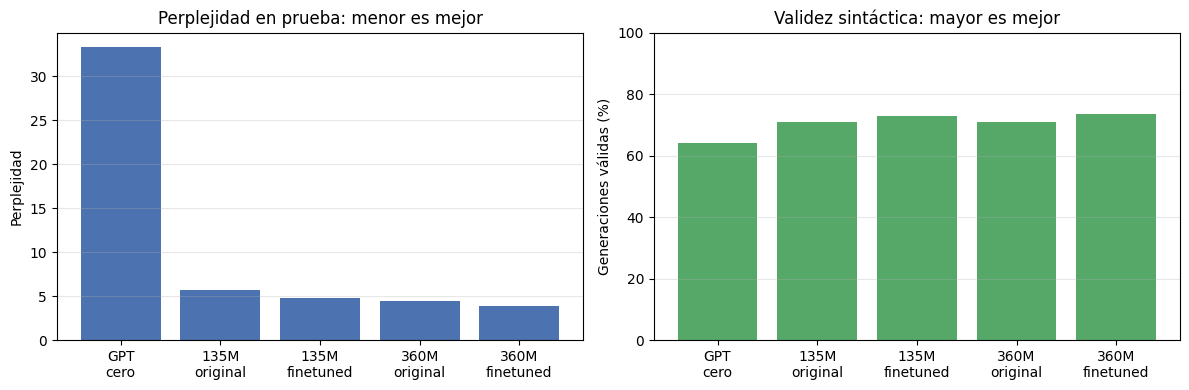

'respaldo/comparacion_modelos.png'

In [35]:
short_labels = [
    "GPT\ncero",
    "135M\noriginal",
    "135M\nfinetuned",
    "360M\noriginal",
    "360M\nfinetuned"
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    short_labels,
    final_results_df["Perplejidad"],
    color="#4C72B0"
)
axes[0].set_title("Perplejidad en prueba: menor es mejor")
axes[0].set_ylabel("Perplejidad")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    short_labels,
    final_results_df["Validez_sintactica_pct"],
    color="#55A868"
)
axes[1].set_title("Validez sintáctica: mayor es mejor")
axes[1].set_ylabel("Generaciones válidas (%)")
axes[1].set_ylim(0, 100)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()

figure_path = "resultados/comparacion_modelos.png"

plt.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight"
)
plt.show()

shutil.copy2(
    figure_path,
    os.path.join(
        BACKUP_DIR,
        os.path.basename(figure_path)
    )
)


## Análisis comparativo

### Efecto del finetuning

El finetuning completo redujo la perplejidad sobre prueba en ambos tamaños.
En SmolLM2-135M pasó de 5.7053 a 4.7423, una reducción aproximada del 16.9%.
En SmolLM2-360M pasó de 4.3929 a 3.8359, una reducción aproximada del 12.7%.

Estos resultados indican que, bajo el protocolo utilizado, los modelos
finetuneados asignan mayor probabilidad a los tokens del corpus de prueba
que sus respectivas versiones originales.

### Comparación entre tamaños

SmolLM2-360M obtuvo menor perplejidad que SmolLM2-135M tanto antes como
después del finetuning. Incluso el 360M original, con perplejidad de 4.3929,
superó al 135M finetuned, cuya perplejidad fue de 4.7423.

El mejor resultado predictivo correspondió al 360M finetuned, con
perplejidad de 3.8359. Sin embargo, su entrenamiento requirió más tiempo:
28.67 minutos frente a 13.4 minutos del 135M, según los tiempos registrados
para entrenamiento y validación final.

### Modelo entrenado desde cero

El GPT desde cero obtuvo una perplejidad de 33.3032, considerablemente mayor
que la de las configuraciones preentrenadas.

Esta diferencia es compatible con la ventaja del preentrenamiento, pero
el experimento no permite atribuirla exclusivamente a ese factor:
también cambian el tamaño, la arquitectura y el historial de entrenamiento
de los modelos comparados.

### Validez sintáctica

El porcentaje de generaciones sintácticamente válidas fue del 64.0% para
el GPT desde cero, del 71.0% para ambos modelos originales, del 73.0%
para el 135M finetuned y del 73.5% para el 360M finetuned.

El finetuning produjo mejoras observadas de 2 y 2.5 puntos porcentuales
en los modelos de 135M y 360M, respectivamente.

Estas diferencias deben interpretarse con cautela: la evaluación utiliza
200 ejemplos, y no se realizó una prueba estadística. La diferencia entre
los dos modelos finetuneados corresponde solamente a una generación válida.

### Alcance y limitaciones de la evaluación

Todas las configuraciones se evaluaron sobre los mismos 348075 tokens
objetivo y los mismos 200 prompts de prueba.

La validez sintáctica se calculó mediante ast.parse sobre el prompt y su
continuación, aplicando el recorte de la última línea cuando correspondía.
No se ejecutó el código ni se comprobó que resolviera una tarea.

Un resultado sintácticamente válido puede contener comentarios, cadenas
de texto, repeticiones o instrucciones sin utilidad funcional. Por tanto,
el porcentaje de validez no debe interpretarse como porcentaje de
programas correctos.

Los resultados describen este subconjunto del corpus y este protocolo
de generación greedy, con prompts de 64 tokens y hasta 128 tokens nuevos.
No se evaluó su sensibilidad a otras semillas, prompts o estrategias
de decodificación.

### Consideraciones adicionales del protocolo

La segmentación descarta menos de 256 tokens sobrantes por partición y no evalúa el primer token de cada bloque como objetivo. Por ello, el reporte corresponde a los 348.075 objetivos definidos por los bloques de prueba, no a cada posición posible de los archivos completos.

No se realizó deduplicación adicional entre particiones ni auditoría de contaminación respecto al preentrenamiento. Los prompts cortos pueden estar dominados por licencias y comentarios; la aceptación por ast.parse no garantiza que la continuación contenga instrucciones útiles.

# Generación de ejemplos

Se presentan tres ejemplos de cada modelo entrenado: GPT desde cero, SmolLM2-135M finetuned y SmolLM2-360M finetuned. Se utilizan los mismos tres prompts para los tres modelos, en el orden de la muestra de evaluación, sin selección por calidad. Las continuaciones son las salidas originales del bucle autorregresivo propio.

## Selección de los ejemplos

Se presentan las salidas registradas de los primeros tres prompts de la muestra fija para cada modelo entrenado, sin seleccionar por validez ni regenerar. La función autorregresiva usada es `generate_code_batch`, definida antes de su primera utilización en la sección de evaluación.

Se distingue el prefijo de la continuación; ambos deben concatenarse antes de verificar sintaxis. Los ejemplos se conservan como texto para que puedan leerse sin cargar archivos JSON ni volver a ejecutar inferencia. La etiqueta de validez corresponde al texto tras aplicar el tratamiento de truncamiento documentado en el protocolo.

## GPT desde cero

### Ejemplo 1

Índice del archivo de prueba: 654

Tokens nuevos: 128  
Motivo de parada: `token_limit`  
Sintaxis válida: `True`  
Última línea recortada: `True`

La validez indicada corresponde al texto completo después del tratamiento del truncamiento, no a la continuación aislada.

#### Prefijo original

```python
#    Licensed under the Apache License, Version 2.0 (the "License"); you may
#    not use this file except in compliance with the License. You may obtain
#    a copy of the License at
#
#         http://www.apache.org/licenses/LICENSE-2
```

#### Continuación generada

```python
.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

from __future__ import absolute_import
from __future__ import division
from __future__ import division
from __future__ import print_function

from __future__ import print_function

from __future__ import print_function

from __future__ import
```

### Ejemplo 2

Índice del archivo de prueba: 114

Tokens nuevos: 128  
Motivo de parada: `token_limit`  
Sintaxis válida: `True`  
Última línea recortada: `True`

La validez indicada corresponde al texto completo después del tratamiento del truncamiento, no a la continuación aislada.

#### Prefijo original

```python
# -*- coding: utf-8 -*-

# Copyright 2012 splinter authors. All rights reserved.
# Use of this source code is governed by a BSD-style
# license that can be found in the LICENSE file.

from selenium.webdriver import Firefox
from selenium.
```

#### Continuación generada

```python
core.utils import BaseCommand
from django.contrib.models import models
from django.models import models
from django.models import models
from django.models.models.models import models
from django.models import models
from django.models import models
from django.models.models import models

from django.models import models
from django.models.models import models
from django.models import models
from django.models import models
from django.models import models

from django.models import models
from django.models.models.models.models.models.models.models import models
```

### Ejemplo 3

Índice del archivo de prueba: 25

Tokens nuevos: 128  
Motivo de parada: `token_limit`  
Sintaxis válida: `True`  
Última línea recortada: `True`

La validez indicada corresponde al texto completo después del tratamiento del truncamiento, no a la continuación aislada.

#### Prefijo original

```python
#!/usr/bin/python
# -*- coding: utf-8 -*-

# (c) 2012, Michael DeHaan <michael.dehaan@gmail.com>
#
# This file is part of Ansible
#
# Ansible is free
```

#### Continuación generada

```python
 software: you can redistribute it and/or modify
# it under the terms of the GNU General Public License as published by
# the Free Software Foundation, either version 3 of the License, or
# (at your option) any later version.
#
# Ansible is distributed in the hope that it will be useful,
# but WITHOUT ANY WARRANTY; without even the implied warranty of
# MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
# GNU General Public License for more details.
#
# You should have received a copy of the GNU General Public License
# along with Ansible
```

## SmolLM2-135M finetuned

### Ejemplo 1

Índice del archivo de prueba: 654

Tokens nuevos: 128  
Motivo de parada: `token_limit`  
Sintaxis válida: `True`  
Última línea recortada: `True`

La validez indicada corresponde al texto completo después del tratamiento del truncamiento, no a la continuación aislada.

#### Prefijo original

```python
#    Licensed under the Apache License, Version 2.0 (the "License"); you may
#    not use this file except in compliance with the License. You may obtain
#    a copy of the License at
#
#         http://www.apache.org/licenses/LICENSE-2
```

#### Continuación generada

```python
.0
#
#    Unless required by applicable law or agreed to in writing, software
#    distributed under the License is distributed on an "AS IS" BASIS, WITHOUT
#    WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied. See the
#    License for the specific language governing permissions and limitations
#    under the License.

from django.conf import settings
from django.db import migrations, models
from django.db.models import Q
from django.utils.encoding import python_2_unicode_compatible

# vim:expandtab:smartindent:tabstop
```

### Ejemplo 2

Índice del archivo de prueba: 114

Tokens nuevos: 128  
Motivo de parada: `token_limit`  
Sintaxis válida: `True`  
Última línea recortada: `True`

La validez indicada corresponde al texto completo después del tratamiento del truncamiento, no a la continuación aislada.

#### Prefijo original

```python
# -*- coding: utf-8 -*-

# Copyright 2012 splinter authors. All rights reserved.
# Use of this source code is governed by a BSD-style
# license that can be found in the LICENSE file.

from selenium.webdriver import Firefox
from selenium.
```

#### Continuación generada

```python
webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.common.action_chains import ActionChains
from selenium.common.exceptions import NoSuchElementException
from selenium.common.exceptions import NoSuchElementException
from selenium.common.exceptions import NoSuchURLElementException
from selenium.common.exceptions import NoSuchURLElementException
from selenium.common.exceptions import NoSuchURLElementException
from selenium.common.exceptions import NoSuchURLElementException
from selenium.common.exceptions import NoSuchURLElementException
from selenium
```

### Ejemplo 3

Índice del archivo de prueba: 25

Tokens nuevos: 128  
Motivo de parada: `token_limit`  
Sintaxis válida: `True`  
Última línea recortada: `True`

La validez indicada corresponde al texto completo después del tratamiento del truncamiento, no a la continuación aislada.

#### Prefijo original

```python
#!/usr/bin/python
# -*- coding: utf-8 -*-

# (c) 2012, Michael DeHaan <michael.dehaan@gmail.com>
#
# This file is part of Ansible
#
# Ansible is free
```

#### Continuación generada

```python
 software: you can redistribute it and/or modify
# it under the terms of the GNU General Public License as published by
# the Free Software Foundation, either version 3 of the License, or
# (at your option) any later version.
#
# Ansible is distributed in the hope that it will be useful,
# but WITHOUT ANY WARRANTY; without even the implied warranty of
# MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
# GNU General Public License for more details.
#
# You should have received a copy of the GNU General Public License
# along with Ansible
```

## SmolLM2-360M finetuned

### Ejemplo 1

Índice del archivo de prueba: 654

Tokens nuevos: 128  
Motivo de parada: `token_limit`  
Sintaxis válida: `True`  
Última línea recortada: `True`

La validez indicada corresponde al texto completo después del tratamiento del truncamiento, no a la continuación aislada.

#### Prefijo original

```python
#    Licensed under the Apache License, Version 2.0 (the "License"); you may
#    not use this file except in compliance with the License. You may obtain
#    a copy of the License at
#
#         http://www.apache.org/licenses/LICENSE-2
```

#### Continuación generada

```python
.0
#
#    Unless required by applicable law or agreed to in writing, software
#    distributed under the License is distributed on an "AS IS" BASIS, WITHOUT
#    WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied. See the
#    License for the specific language governing permissions and limitations
#    under the License.

from __future__ import absolute_import
from __future__ import division
from __future__ import print_function

from tensorflow.python.framework import ops
from tensorflow.python.platform import test

from tensorflow.python.platform import test
```

### Ejemplo 2

Índice del archivo de prueba: 114

Tokens nuevos: 128  
Motivo de parada: `token_limit`  
Sintaxis válida: `True`  
Última línea recortada: `True`

La validez indicada corresponde al texto completo después del tratamiento del truncamiento, no a la continuación aislada.

#### Prefijo original

```python
# -*- coding: utf-8 -*-

# Copyright 2012 splinter authors. All rights reserved.
# Use of this source code is governed by a BSD-style
# license that can be found in the LICENSE file.

from selenium.webdriver import Firefox
from selenium.
```

#### Continuación generada

```python
webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.common.action_chains import ActionChains
from selenium.webdriver.common.action_chains import ActionChains
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.common.keys import Keys
from selenium.
```

### Ejemplo 3

Índice del archivo de prueba: 25

Tokens nuevos: 128  
Motivo de parada: `token_limit`  
Sintaxis válida: `True`  
Última línea recortada: `True`

La validez indicada corresponde al texto completo después del tratamiento del truncamiento, no a la continuación aislada.

#### Prefijo original

```python
#!/usr/bin/python
# -*- coding: utf-8 -*-

# (c) 2012, Michael DeHaan <michael.dehaan@gmail.com>
#
# This file is part of Ansible
#
# Ansible is free
```

#### Continuación generada

```python
 software: you can redistribute it and/or modify
# it under the terms of the GNU General Public License as published by
# the Free Software Foundation, either version 3 of the License, or
# (at your option) any later version.
#
# Ansible is distributed in the hope that it will be useful,
# but WITHOUT ANY WARRANTY; without even the implied warranty of
# MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
# GNU General Public License for more details.
#
# You should have received a copy of the GNU General Public License
# along with Ansible
```

## Análisis cualitativo de las salidas registradas

Los tres prompts seleccionados corresponden a los índices 654, 114 y 25 de la partición de prueba. Dos comienzan en cabeceras de licencia y uno en importaciones. Esto limita la diversidad funcional de los nueve ejemplos, aunque la selección es idéntica para los tres modelos y no depende de su calidad.

- En el primer prompt, el GPT desde cero repite importaciones de `__future__`; el 135M introduce importaciones de Django y el 360M de TensorFlow, sin que se haya comprobado su pertinencia o disponibilidad.
- En el segundo prompt, el GPT desde cero produce rutas de importación repetitivas relacionadas con Django. Los modelos finetuneados continúan con importaciones asociadas a Selenium, pero también presentan repeticiones; el 135M genera nombres como `NoSuchURLElementException` cuya existencia no se validó.
- En el tercer prompt, los tres modelos prolongan principalmente el texto de licencia. Una continuación de comentarios puede pasar ast.parse sin implementar funcionalidad.

Estos ejemplos muestran que la coherencia superficial y la aceptación sintáctica no equivalen a resolver una tarea de programación. No se ejecutaron importaciones ni se verificaron dependencias o comportamiento de las generaciones.

# Conclusiones

1. El finetuning completo mejoró la capacidad predictiva de ambos modelos
   SmolLM2 sobre el conjunto de prueba. La perplejidad disminuyó de 5.7053
   a 4.7423 en el modelo de 135M y de 4.3929 a 3.8359 en el de 360M.

2. SmolLM2-360M finetuned obtuvo la menor perplejidad. Su ventaja se
   acompañó de un mayor tiempo de entrenamiento y validación final:
   28.67 minutos frente a 13.4 minutos del modelo de 135M.

3. El GPT entrenado desde cero obtuvo una perplejidad de 33.3032.
   En las condiciones del experimento, no alcanzó el desempeño de los
   modelos preentrenados. La comparación incluye diferencias de tamaño,
   arquitectura e historial de entrenamiento.

4. La validez sintáctica aumentó del 71.0% al 73.0% en el modelo de 135M
   y del 71.0% al 73.5% en el de 360M. Estas mejoras observadas son pequeñas
   y no se presentan como evidencia estadística concluyente.

5. Para limitar el sobreajuste se utilizaron particiones por archivos,
   validación separada, weight decay y un número reducido de épocas.
   En el GPT se seleccionó el checkpoint con menor pérdida de validación.
   En los modelos SmolLM2 se comparó la validación antes y después de una
   época completa. Las mediciones disponibles no muestran deterioro final
   de validación, pero no descartan sobreajuste ni permiten estudiar
   exhaustivamente su evolución.

6. La evaluación sintáctica no verifica corrección funcional. El código
   generado no se ejecutó, y una salida aceptada por ast.parse puede no
   implementar una solución útil.

7. Las principales limitaciones son el tamaño del subconjunto, el contexto
   de 256 tokens, una sola ejecución de entrenamiento por configuración,
   una muestra de 200 prompts y el uso de una única estrategia de
   decodificación. No se midió la variabilidad entre ejecuciones ni se
   garantizó la ausencia de ejemplos similares en el preentrenamiento
   de SmolLM2.

## Síntesis y trabajo futuro

La evidencia más consistente es la reducción de perplejidad tras el finetuning en ambos tamaños. La mejora sintáctica es modesta y los ejemplos revelan repeticiones e influencia de las cabeceras de licencia.

Como trabajo futuro sería útil evaluar múltiples semillas, auditar duplicados, seleccionar prompts funcionales en un conjunto adicional independiente y utilizar pruebas de comportamiento en un entorno aislado. Estas extensiones no se realizaron en el presente experimento y no alteran el protocolo reportado.